In [1]:
2+2

4

In [4]:
import os
import json
from pathlib import Path

import random
import pandas as pd
import numpy as np
import torch
import seaborn as sns
import matplotlib.pyplot as plt
import cv2
from tqdm import tqdm


In [3]:
ssv2_path = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2"
ek100_path = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/epic_kitchens_100"
print(ssv2_path)
print(ek100_path)

/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2
/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/epic_kitchens_100


# ssv2

In [ ]:
# from the test-answers.csv file
videos = [
208583, #Moving something closer to something
50058, #Stacking number of something
139625, #Putting something similar to other things that are already on the table
40500, #Rolling something on a flat surface
79958, #Moving something across a surface without it falling down
174783, #Putting something on a surface
117998, #Tearing something just a little bit
148399, #Pouring something out of something
77635, #Tipping something over
192072, #Showing that something is inside something
86893, #Taking something from somewhere
218388, #Rolling something on a flat surface
95573, #Pushing something from left to right
130318, #Tearing something just a little bit
]

for vid in videos:
    1
    # os.system(f"cp {ssv2_path}/clips/{vid}.webm ./clips_ssv2/")

In [13]:
ssv2_path + "/labels/test.json"

'/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2/labels/test.json'

In [17]:
with open(ssv2_path + "/labels/labels.json", "r") as f:
    labels = json.loads(f)

labels

PermissionError: [Errno 13] Permission denied: '/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2/labels/labels.json'

In [6]:
# inspect video properties and load frames into PyTorch tensors
from pathlib import Path
import cv2
import torch
import numpy as np
import pandas as pd
from tqdm import tqdm

ssv2_path = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2"
ssv2_path

'/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2'

In [5]:
video_files = list(Path(ssv2_path).glob("*.webm"))
video_files

[PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/117998.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/130318.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/139625.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/148399.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/174783.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/192072.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/208583.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/218388.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2/40500.webm'),
 PosixPath('/user/h.siddiqui/u27673/.p

In [7]:
video_path = video_files[0]

cap = cv2.VideoCapture(str(video_path))
if not cap.isOpened():
    raise ValueError(f"Unable to open video: {video_path}")

# Extract metadata properties
fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration = frame_count / fps if fps > 0 else 0.0

metadata = {
    "video_name": Path(video_path).name,
    "fps": round(fps, 2),
    "frame_count": frame_count,
    "width": width,
    "height": height,
    "aspect_ratio": round(width / height, 2) if height > 0 else 0,
    "duration_sec": round(duration, 2)
}
metadata

{'video_name': '117998.webm',
 'fps': 12.0,
 'frame_count': 55,
 'width': 427,
 'height': 240,
 'aspect_ratio': 1.78,
 'duration_sec': 4.58}

In [ ]:
# def inspect_and_load_video(video_path, max_frames=None):
#     """
#     Reads video metadata and optionally loads frames into a PyTorch Tensor (T, C, H, W).
#     """
#     cap = cv2.VideoCapture(str(video_path))
#     if not cap.isOpened():
#         raise ValueError(f"Unable to open video: {video_path}")
        
#     # Extract metadata properties
#     fps = cap.get(cv2.CAP_PROP_FPS)
#     frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
#     width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
#     height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
#     duration = frame_count / fps if fps > 0 else 0.0
    
#     metadata = {
#         "video_name": Path(video_path).name,
#         "fps": round(fps, 2),
#         "frame_count": frame_count,
#         "width": width,
#         "height": height,
#         "aspect_ratio": round(width / height, 2) if height > 0 else 0,
#         "duration_sec": round(duration, 2)
#     }
    
#     # Read frames if required
#     frames = []
#     read_limit = max_frames if max_frames else frame_count
    
#     while cap.isOpened() and len(frames) < read_limit:
#         ret, frame = cap.read()
#         if not ret:
#             break
#         # OpenCV reads BGR -> convert to RGB
#         frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
#         frames.append(frame_rgb)
        
#     cap.release()
    
#     if len(frames) == 0:
#         return metadata, None
        
#     # Stack into NumPy array (T, H, W, C), uint8
#     frames_np = np.stack(frames)
    
#     # Convert to PyTorch Tensor (T, C, H, W)
#     frames_tensor = torch.from_numpy(frames_np).permute(0, 3, 1, 2)
    
#     return metadata, frames_tensor

In [7]:
def get_video_metadata(video_path):
    """
    Reads video metadata and optionally loads frames into a PyTorch Tensor (T, C, H, W).
    """
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise ValueError(f"Unable to open video: {video_path}")
        
    # Extract metadata properties
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    duration = frame_count / fps if fps > 0 else 0.0
    
    metadata = {
        "video_name": Path(video_path).name,
        "fps": round(fps, 2),
        "frame_count": frame_count,
        "width": width,
        "height": height,
        "aspect_ratio": round(width / height, 2) if height > 0 else 0,
        "duration_sec": round(duration, 2)
    }
    
    return metadata

In [8]:
ssv2_path = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/testing/clips_ssv2"
video_files = list(Path(ssv2_path).glob("*.webm"))  # SSv2 is typically .webm or .mp4

stats_list = []

# Scan metadata
for video_file in tqdm(video_files, desc="Scanning videos"):
    meta = get_video_metadata(video_file)
    stats_list.append(meta)

# Create DataFrame for analysis
df = pd.DataFrame(stats_list)
print(df)
print(df.describe())

Scanning videos: 100%|██████████| 14/14 [00:00<00:00, 26.03it/s]


     video_name   fps  frame_count  width  height  aspect_ratio  duration_sec
0   117998.webm  12.0           55    427     240          1.78          4.58
1   130318.webm  12.0           72    427     240          1.78          6.00
2   139625.webm  12.0           37    320     240          1.33          3.08
3   148399.webm  12.0           51    427     240          1.78          4.25
4   174783.webm  12.0           38    427     240          1.78          3.17
5   192072.webm  12.0           53    427     240          1.78          4.42
6   208583.webm  12.0           48    427     240          1.78          4.00
7   218388.webm  12.0           14    293     240          1.22          1.17
8    40500.webm  12.0           23    293     240          1.22          1.92
9    50058.webm  12.0           44    427     240          1.78          3.67
10   77635.webm  12.0           65    427     240          1.78          5.42
11   79958.webm  12.0           47    427     240          1.78 

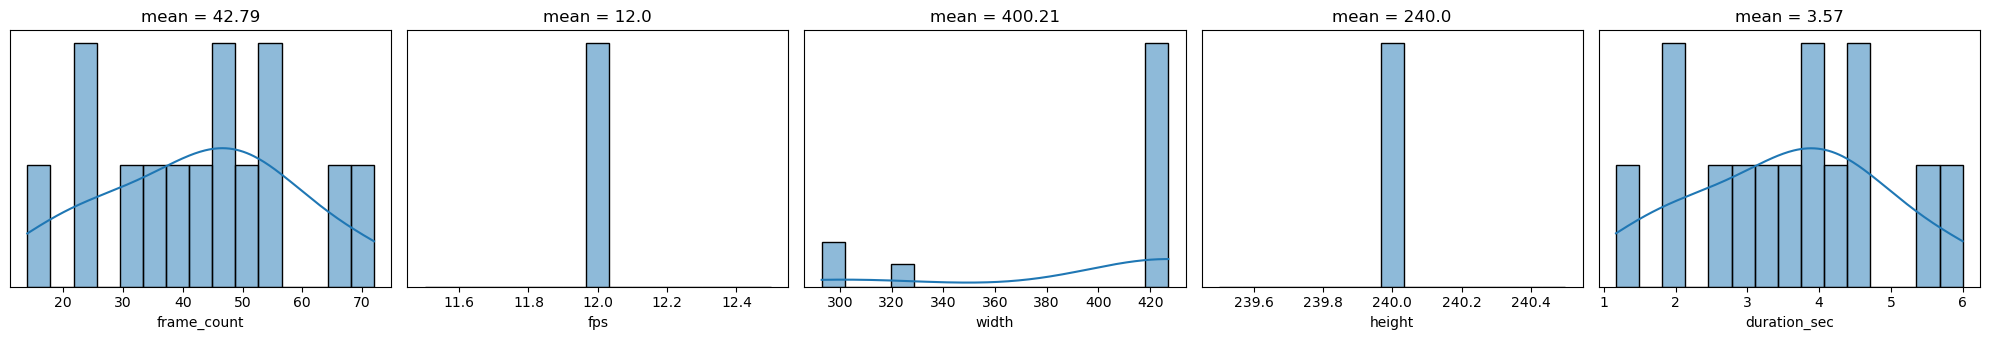

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
cols = ["frame_count", "fps",  "width", "height", "duration_sec"]

for ax, col in zip(axes, cols):    
    sns.histplot(data=df, x=col, ax=ax, kde=True, bins=15).set_title(f"mean = {round(df[col].mean(), 2)}")
    ax.yaxis.set_visible(False)

plt.tight_layout()
plt.show()

In [12]:
ssv2_path = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2/clips/"
video_files = list(Path(ssv2_path).glob("*.webm"))  # SSv2 is typically .webm or .mp4
len(video_files)

220847

In [16]:
import random
random.sample(video_files, 3)

[PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2/clips/27962.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2/clips/40472.webm'),
 PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2/clips/36143.webm')]

In [17]:
stats_list = []

# Scan metadata
for video_file in tqdm(random.sample(video_files, 20000), desc="Scanning videos"):
    meta = get_video_metadata(video_file)
    stats_list.append(meta)

# Create DataFrame for analysis
df = pd.DataFrame(stats_list)
print(df.describe())

Scanning videos: 100%|██████████| 20000/20000 [06:35<00:00, 50.52it/s] 


           fps   frame_count         width   height  aspect_ratio  \
count  20000.0  20000.000000  20000.000000  20000.0  20000.000000   
mean      12.0     45.858300    393.104500    240.0      1.637843   
std        0.0     12.615949     48.815204      0.0      0.204923   
min       12.0      8.000000    135.000000    240.0      0.560000   
25%       12.0     36.000000    360.000000    240.0      1.500000   
50%       12.0     46.000000    427.000000    240.0      1.780000   
75%       12.0     56.000000    427.000000    240.0      1.780000   
max       12.0     86.000000    480.000000    240.0      2.000000   

       duration_sec  
count  20000.000000  
mean       3.821530  
std        1.051322  
min        0.670000  
25%        3.000000  
50%        3.830000  
75%        4.670000  
max        7.170000  


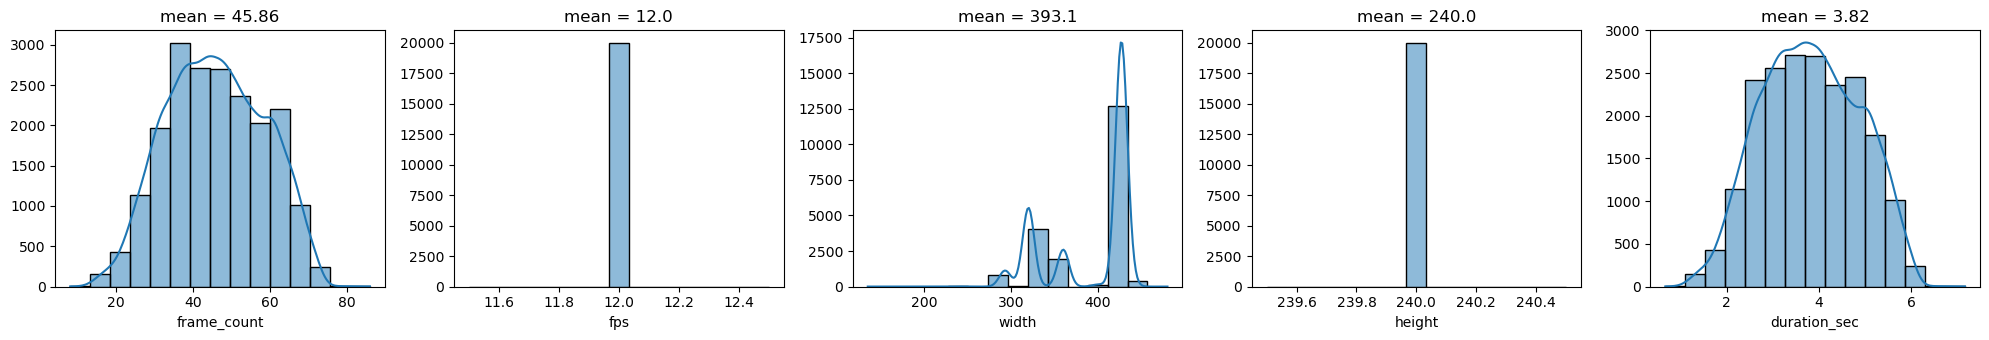

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
cols = ["frame_count", "fps",  "width", "height", "duration_sec"]

for ax, col in zip(axes, cols):    
    sns.histplot(data=df, x=col, ax=ax, kde=True, bins=15).set_title(f"mean = {round(df[col].mean(), 2)}")
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

# ek100

In [ ]:
# from train.txt
videos = [
"P01_01_0.mp4", # 3
"P01_01_1.mp4", # 6
"P01_01_100.mp4", # 0
"P01_01_104.mp4", # 1
"P01_01_106.mp4", # 5
"P01_01_107.mp4", # 4
"P01_01_110.mp4", # 1
"P01_01_111.mp4", # 3
"P01_01_118.mp4", # 10
"P01_01_12.mp4", # 1
"P01_01_122.mp4", # 5
"P01_01_123.mp4", # 4
"P01_01_125.mp4", # 10
"P01_01_130.mp4", # 59
"P01_01_131.mp4", # 77
"P01_01_136.mp4", # 13
"P01_01_145.mp4", # 23
"P01_01_147.mp4", # 9
"P01_01_148.mp4", # 38
"P01_01_190.mp4", # 7
"P01_01_197.mp4", # 13
"P01_01_205.mp4", # 28
"P01_01_222.mp4", # 17
"P01_01_223.mp4", # 10
"P01_01_236.mp4", # 12
"P01_01_259.mp4", # 60
"P01_01_270.mp4", # 72
"P01_01_272.mp4", # 16
"P01_01_277.mp4", # 37
]

for vid in videos:
    1
    # os.system(f"cp {ek100_path}/clips/{vid} ./clips_ek100/")


In [21]:
ek100_path = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/epic_kitchens_100/clips/"
video_files = list(Path(ek100_path).glob("*.mp4"))
len(video_files)

89977

In [22]:
stats_list = []

# Scan metadata
for video_file in tqdm(random.sample(video_files, 20000), desc="Scanning videos"):
    meta = get_video_metadata(video_file)
    stats_list.append(meta)

# Create DataFrame for analysis
df = pd.DataFrame(stats_list)
print(df.describe())

Scanning videos: 100%|██████████| 20000/20000 [04:42<00:00, 70.86it/s] 


                fps   frame_count         width   height  aspect_ratio  \
count  20000.000000  20000.000000  20000.000000  20000.0  20000.000000   
mean      54.324000    171.361500    683.957000    384.0      1.779888   
std        4.954215    299.839574      2.719287      0.0      0.007114   
min       50.000000     11.000000    512.000000    384.0      1.330000   
25%       50.000000     53.000000    684.000000    384.0      1.780000   
50%       50.000000     87.000000    684.000000    384.0      1.780000   
75%       60.000000    172.000000    684.000000    384.0      1.780000   
max       60.000000  14858.000000    684.000000    384.0      1.780000   

       duration_sec  
count  20000.000000  
mean       3.107490  
std        5.476555  
min        0.220000  
25%        1.000000  
50%        1.600000  
75%        3.120000  
max      297.160000  


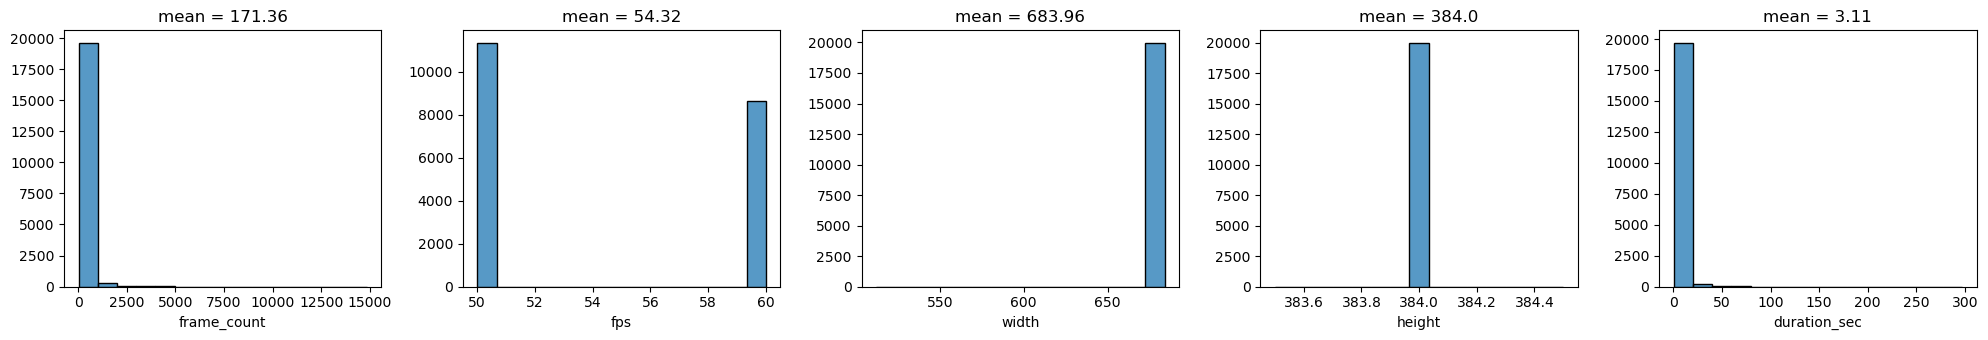

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
cols = ["frame_count", "fps",  "width", "height", "duration_sec"]

for ax, col in zip(axes, cols):    
    sns.histplot(data=df, x=col, ax=ax, bins=15).set_title(f"mean = {round(df[col].mean(), 2)}")
    ax.set_ylabel('')
    
plt.tight_layout()
plt.show()

# Label Analysis

## ssv2 labels

In [5]:
ssv2_path = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2"
labels_dir = Path(ssv2_path) / "labels"
labels_dir

PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2/labels')

In [ ]:
# SSv2 annotations use train.json and validation.json
train_file = labels_dir / "train.json"
val_file = labels_dir / "validation.json"

with open(train_file, 'r') as f:
    train_raw = json.load(f)

with open(val_file, 'r') as f:
    val_raw = json.load(f)

train_raw[0:2] # train_raw is a list. i am printing first 2 elements which are training examples.

[{'id': '78687',
  'label': 'holding potato next to vicks vaporub bottle',
  'template': 'Holding [something] next to [something]',
  'placeholders': ['potato', 'vicks vaporub bottle']},
 {'id': '42326',
  'label': 'spreading margarine onto bread',
  'template': 'Spreading [something] onto [something]',
  'placeholders': ['margarine', 'bread']}]

In [14]:
df_train = pd.DataFrame(train_raw)
df_train['split'] = 'train'

df_val = pd.DataFrame(val_raw)
df_val['split'] = 'val'

df = pd.concat([df_train, df_val], ignore_index=True)
df.head(3)

,id,label,template,placeholders,split
0,78687,holding potato next to vicks vaporub bottle,Holding [something] next to [something],"[potato, vicks vaporub bottle]",train
1,42326,spreading margarine onto bread,Spreading [something] onto [something],"[margarine, bread]",train
2,100904,putting pen on a surface,Putting [something] on a surface,[pen],train


In [40]:
print(f"Total Train Samples: {len(df_train):,}")
print(f"Total Val Samples:   {len(df_val):,}")
df.split.value_counts(1)*100

Total Train Samples: 168,913
Total Val Samples:   24,777


split
train    87.20791
val      12.79209
Name: proportion, dtype: float64

In [41]:
print(f"Unique Templates:{df['template'].nunique()}")

Unique Templates:174


/tmp/ipykernel_1892669/3500712344.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top15, y='template', x='count', palette='viridis', ax=ax)


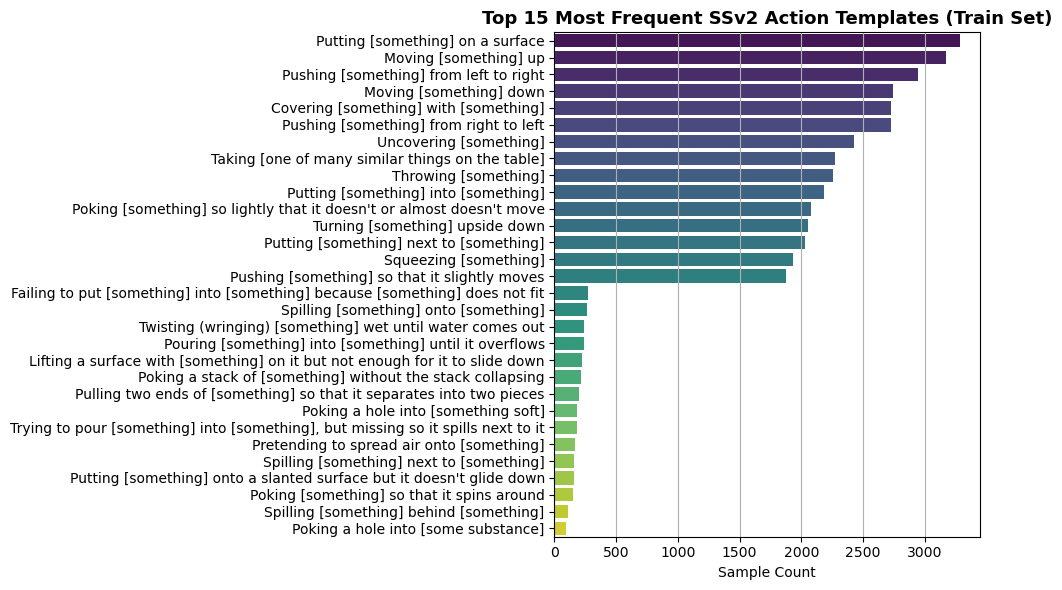

In [37]:
# top 15 and bottom 15 class counts (Train)
train_counts = df_train['template'].value_counts()

top15 = train_counts.head(15).reset_index()
bottom15 = train_counts.tail(15).reset_index()
top15 = pd.concat([top15, bottom15]).reset_index(drop=True)
top15.columns = ['template', 'count']

fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(zorder=0)
sns.barplot(data=top15, y='template', x='count', palette='viridis', ax=ax)

ax.set_title("Top 15 Most Frequent SSv2 Action Templates (Train Set)", fontsize=13, fontweight='bold')
ax.set_xlabel("Sample Count")
ax.set_ylabel('')  # Clear y-axis label text

plt.tight_layout()
plt.show()

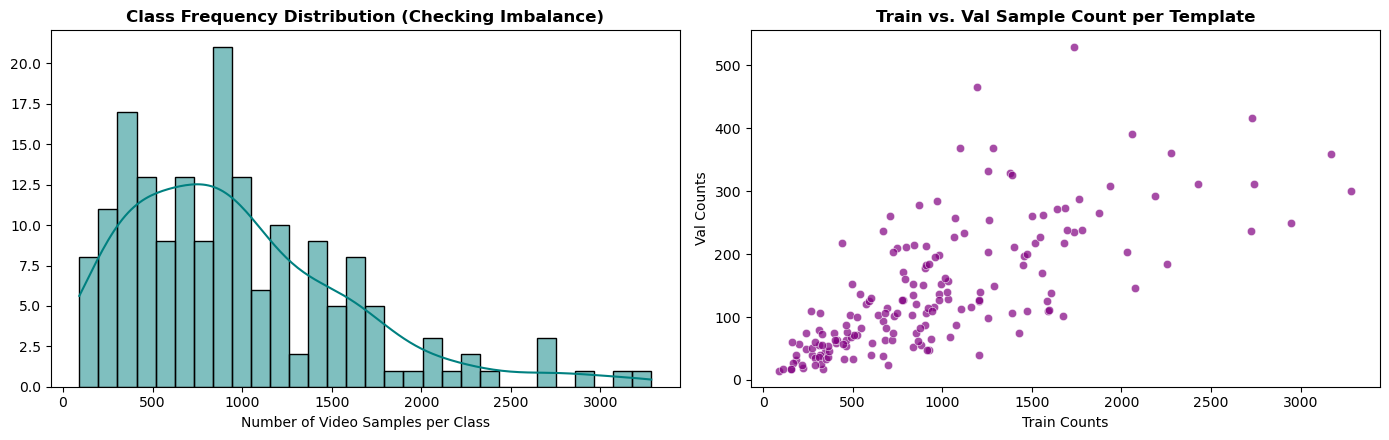

In [ ]:
## Gemini AI code below: Long-Tail Distribution & Train/Val Split Consistency for ssv2 dataset
# Group class frequencies by split
class_counts = df.groupby(['template', 'split']).size().reset_index(name='count')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot 1: Class frequency distribution curve (Long-tail inspection)
sns.histplot(data=df_train['template'].value_counts(), kde=True, ax=axes[0], color='teal', bins=30)
axes[0].set_title("Class Frequency Distribution (Checking Imbalance)", fontweight='bold')
axes[0].set_xlabel("Number of Video Samples per Class")
axes[0].set_ylabel('')

# Plot 2: Compare train vs val sample counts across classes
sns.scatterplot(
    data=df.groupby('template')['split'].value_counts().unstack().fillna(0),
    x='train', y='val', alpha=0.7, color='purple', ax=axes[1]
)
axes[1].set_title("Train vs. Val Sample Count per Template", fontweight='bold')
axes[1].set_xlabel("Train Counts")
axes[1].set_ylabel("Val Counts")

plt.tight_layout()
plt.show()

## ek100 labels

In [ ]:
ek100_path = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/epic_kitchens_100"
ek_dir = Path(ek100_path)

# 1. Load verb ID to verb name mapping
verb_csv = ek_dir / "generalization" / "EPIC_100_verb_classes.csv"
verbs_df = pd.read_csv(verb_csv, header=0, usecols=[0, 1], names=['verb_id', 'verb_name'])

verbs_df.head(2)

,verb_id,verb_name
0,0,take
1,1,put


In [60]:
verb_map = dict(zip(verbs_df['verb_id'], verbs_df['verb_name']))

In [61]:
# 2. Load train.txt and val.txt (space-separated: video_name, verb_id)
df_train = pd.read_csv(ek_dir / "train.txt", sep=r'\s+', header=None, names=['video', 'verb_id'])
df_train['split'] = 'train'

df_val = pd.read_csv(ek_dir / "val.txt", sep=r'\s+', header=None, names=['video', 'verb_id'])
df_val['split'] = 'val'

# Combine splits and map verb IDs to text names
df = pd.concat([df_train, df_val], ignore_index=True)
df['verb_name'] = df['verb_id'].map(verb_map)

df

,video,verb_id,split,verb_name
0,P01_01_0.mp4,3,train,open
1,P01_01_1.mp4,6,train,turn-on
2,P01_01_10.mp4,3,train,open
3,P01_01_100.mp4,0,train,take
4,P01_01_101.mp4,3,train,open
...,...,...,...,...
76880,P32_10_5.mp4,44,val,spray
76881,P32_10_6.mp4,2,val,wash
76882,P32_10_7.mp4,2,val,wash
76883,P32_10_8.mp4,2,val,wash


In [62]:
print(f"Total Train Clips: {len(df_train):,}")
print(f"Total Val Clips:   {len(df_val):,}")
print(f"Unique Verbs:      {df['verb_id'].nunique()}")

Total Train Clips: 67,217
Total Val Clips:   9,668
Unique Verbs:      97


In [48]:
df.head()

,video,verb_id,split,verb_name
0,P01_01_0.mp4,3,train,NaN
1,P01_01_1.mp4,6,train,NaN
2,P01_01_10.mp4,3,train,NaN
3,P01_01_100.mp4,0,train,NaN
4,P01_01_101.mp4,3,train,NaN


/tmp/ipykernel_1892669/2921884223.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top15_verbs, y='verb_name', x='count', palette='mako', ax=ax)


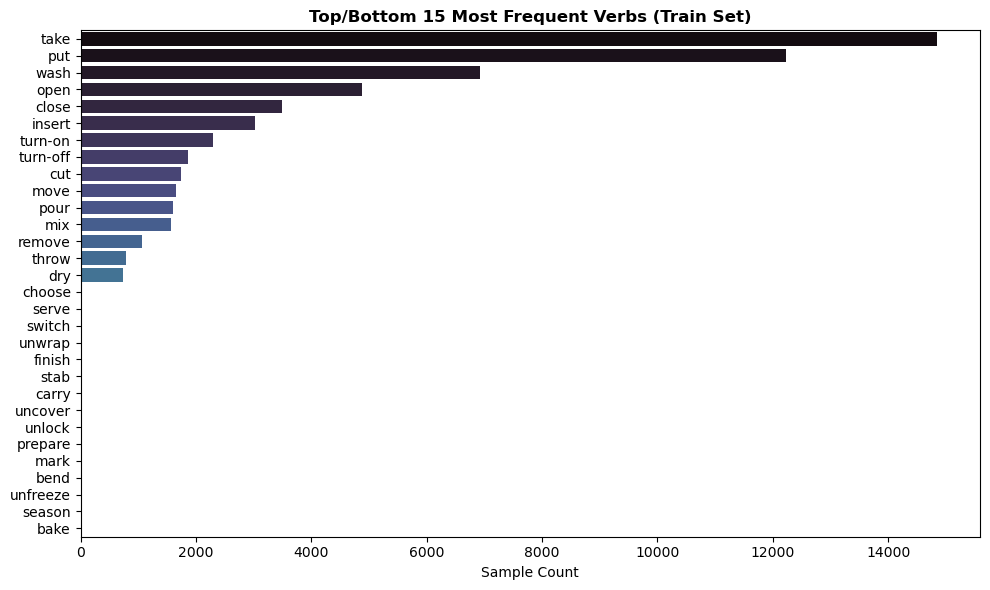

In [67]:
# Top 15 and bottom15 Verbs in Train set
top15_verbs = df[df['split'] == 'train']['verb_name'].value_counts().head(15).reset_index()
bottom15_verbs = df[df['split'] == 'train']['verb_name'].value_counts().tail(15).reset_index()
top15_verbs = pd.concat([top15_verbs, bottom15_verbs]).reset_index(drop=True)

top15_verbs.columns = ['verb_name', 'count']

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top15_verbs, y='verb_name', x='count', palette='mako', ax=ax)

ax.set_title("Top/Bottom 15 Most Frequent Verbs (Train Set)", fontweight='bold')
ax.set_xlabel("Sample Count")
ax.set_ylabel('')

plt.tight_layout()
plt.show()

In [66]:
 df[df['split'] == 'train']['verb_name'].value_counts().tail(15).reset_index()

,verb_name,count
0,choose,13
1,serve,12
2,switch,11
3,unwrap,11
4,finish,11
5,stab,10
6,carry,8
7,uncover,8
8,unlock,6
9,prepare,4


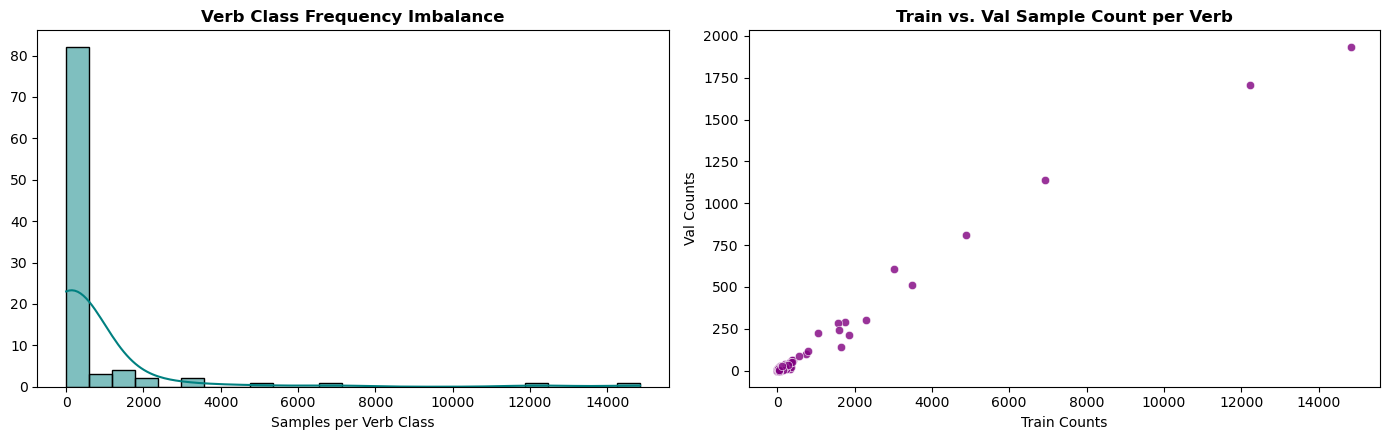

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot 1: Class frequency distribution (Long-tail check)
train_counts = df[df['split'] == 'train']['verb_name'].value_counts()
sns.histplot(train_counts, kde=True, ax=axes[0], color='teal', bins=25)
axes[0].set_title("Verb Class Frequency Imbalance", fontweight='bold')
axes[0].set_xlabel("Samples per Verb Class")
axes[0].set_ylabel('')

# Plot 2: Compare train vs val sample counts per class
split_counts = df.groupby(['verb_name', 'split']).size().unstack(fill_value=0)
sns.scatterplot(data=split_counts, x='train', y='val', alpha=0.8, color='purple', ax=axes[1])
axes[1].set_title("Train vs. Val Sample Count per Verb", fontweight='bold')
axes[1].set_xlabel("Train Counts")
axes[1].set_ylabel("Val Counts")

plt.tight_layout()
plt.show()